In [12]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# import datasets
# this dataset contains the cluster properties (L500, M500, z, etc)
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    comb_data = pickle.load(f)
# this file contains the variances on the L500 measurements
with open('data/REFLEX.p', 'rb') as g:
    errors_dict = pickle.load(g)

In [3]:
# link the variances with the associated clusters
reflex_data = comb_data[comb_data['Sub-Cat']=='REFLEX']
reflex_appended = reflex_data.copy()
reflex_appended['L_err'] = reflex_appended['OName'].apply(lambda x: errors_dict.get(x))
reflex_clean = reflex_appended[reflex_appended['L_err'].notna()]
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


In [4]:
# convert the units of the variances into erg/s
L_err_list = reflex_clean['L_err'].tolist()
variances = (np.array(L_err_list)*1e37*u.W).to(1e44*u.erg/u.s)

In [5]:
# this function takes the dataset and creates instances of the NFWProfile class (defined in another file)
def generate_nfws_from_combined_dataset(dataset, nrows=None):
    cls_data={'M500':dataset['MSZ'],
          'L500':dataset['L500'],
          'z':dataset['z_y'] # take z from Planck
         }
    units={
        'M500': 1e14*u.Msun,
        'L500': 1e37*u.W,
        'z': None
    }

    cls_table=QTable(cls_data, units=units)
    
    n=nrows or len(cls_table)
    
    return [
        NFWProfile(
            cls_table['z'][i],
            M500=cls_table['M500'][i],
            L500=cls_table['L500'][i],
        )
        for i in range(n)
    ]

In [100]:
# log likelihood function for MCMC
def log_lik(p0, obs, variances, nfws, multagn=1):
    log_s0 = p0[0]
    log_mx = p0[1]
    
    # prior
    if log_s0>0 or log_s0<-40:
        return -np.inf
    # DM particle mass is limited to being less than a proton mass
    if log_mx<-4 or 10**log_mx>const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value:
        return -np.inf

    # calculate model predicted L500
    predicted = [nfw.L500_analytic(log_s0, log_mx, mult_agn=multagn) for nfw in nfws]
    X2 = chi_squared(predicted, obs, variances)
    return -X2/2

In [58]:
# for the sake of speed of testing, only look at a subset of the data
ncls = 10
nfws = generate_nfws_from_combined_dataset(reflex_clean[:ncls])
L_obs = [nfw.L500.to(u.erg/u.s) for nfw in nfws][:ncls]

nfws_subset = nfws[:ncls]
vars_subset = variances[:ncls]
obs_subset = L_obs[:ncls]

In [113]:
# initialize a range of values of sigma0 for testing the likelihood function
log_s0 = np.linspace(-40, -25, num=50)

In [114]:
# calculate likelihoods for a few different mx values
log_liks1 = [log_lik([s, -1], obs_subset, vars_subset, nfws_subset) for s in log_s0]
log_liks2 = [log_lik([s, -2], obs_subset, vars_subset, nfws_subset) for s in log_s0]
log_liks4 = [log_lik([s, -4], obs_subset, vars_subset, nfws_subset) for s in log_s0]

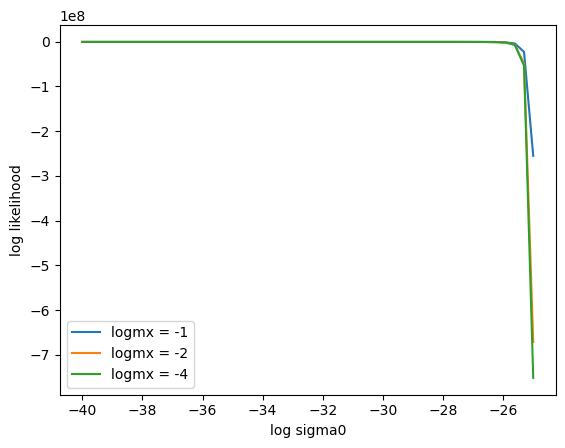

In [115]:
# plot likelihood function as a test (using low agn heating model)
plt.plot(log_s0, log_liks1, label="logmx = -1")
plt.plot(log_s0, log_liks2, label="logmx = -2")
plt.plot(log_s0, log_liks4, label="logmx = -4")

plt.xlabel('log sigma0')
plt.ylabel('log likelihood')
plt.legend()

In [116]:
# calculate likelihoods for a few different mx values, high agn
log_liks1_h = [log_lik([s, -1], obs_subset, vars_subset, nfws_subset, multagn=10) for s in log_s0]
log_liks2_h = [log_lik([s, -2], obs_subset, vars_subset, nfws_subset, multagn=10) for s in log_s0]
log_liks4_h = [log_lik([s, -4], obs_subset, vars_subset, nfws_subset, multagn=10) for s in log_s0]

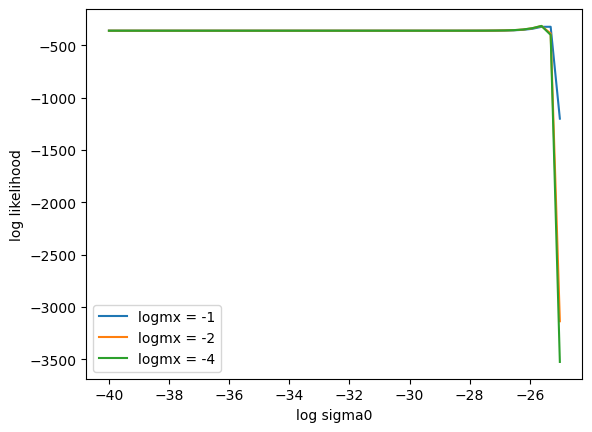

In [117]:
# plot likelihood function as a test (using high agn heating model)
plt.plot(log_s0, log_liks1_h, label="logmx = -1")
plt.plot(log_s0, log_liks2_h, label="logmx = -2")
plt.plot(log_s0, log_liks4_h, label="logmx = -4")

plt.xlabel('log sigma0')
plt.ylabel('log likelihood')
plt.legend()

In [93]:
# prepare MCMC

ndim, nwalkers = 2, 10
initial=np.zeros((nwalkers, ndim ))

# initialize walkers
log_sigma0 = np.random.uniform(low=-40, high=-20, size=nwalkers).astype(np.float128)
log_mp = np.log10(const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value)
log_mx = np.random.uniform(low=-4, high=log_mp, size=nwalkers).astype(np.float128)

initial[:,0]=log_sigma0
initial[:,1]=log_mx
initial

array([[-26.07628168,  -3.80801488],
       [-27.6497274 ,  -1.12871028],
       [-26.82475722,  -2.1644419 ],
       [-35.33436411,  -3.82519858],
       [-38.36426991,  -1.04368897],
       [-31.70334988,  -3.8114198 ],
       [-23.27032498,  -2.3898799 ],
       [-30.41786944,  -0.58399218],
       [-26.7548557 ,  -3.97816985],
       [-37.8181495 ,  -2.3965311 ]])

In [25]:
# for parallelization, check cpus
from multiprocessing import cpu_count

ncpu = cpu_count()
print("{0} CPUs".format(ncpu))

8 CPUs


In [77]:
# with high agn heating model
with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset, 10])
    state = sampler.run_mcmc(initial, 1000, progress=True)

100%|█████████████████████████████████████████| 100/100 [00:03<00:00, 25.40it/s]

Multiprocessing took 4.0 seconds


In [83]:
with Pool() as pool:
    # start sampler after some steps to minimize dependence on initial conditions
    state = sampler.run_mcmc(state, 100000, progress = True)

100%|█████████████████████████████████| 100000/100000 [1:08:09<00:00, 24.45it/s]


(655500, 2)


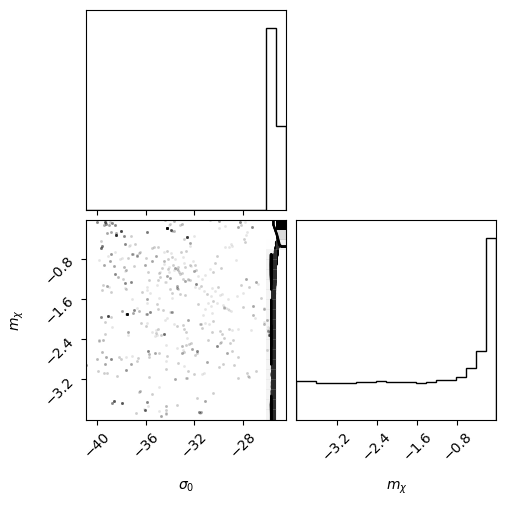

In [84]:
# create corner plot of results
flat_samples = sampler.get_chain(thin=15, flat=True)

print(flat_samples.shape)

labels = [r"$\sigma_0$", r"$m_\chi$"]
fig = corner.corner(
    flat_samples, labels=labels
);

In [88]:
print(
    "Mean acceptance fraction: {0:.3f}".format(
        np.mean(sampler.acceptance_fraction)
    )
)
print(
    "Mean autocorrelation time: {0:.3f} steps".format(
        np.mean(sampler.get_autocorr_time())
    )
)

Mean acceptance fraction: 0.378
Mean autocorrelation time: 2128.946 steps


In [95]:
# with low AGN heating model
with Pool() as pool:
    sampler2 = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    state2 = sampler2.run_mcmc(initial, 1000, progress=True)
    sampler2.run_mcmc(state2, 10000, progress = True)

100%|█████████████████████████████████████| 10000/10000 [13:21<00:00, 12.47it/s]


(7330, 2)


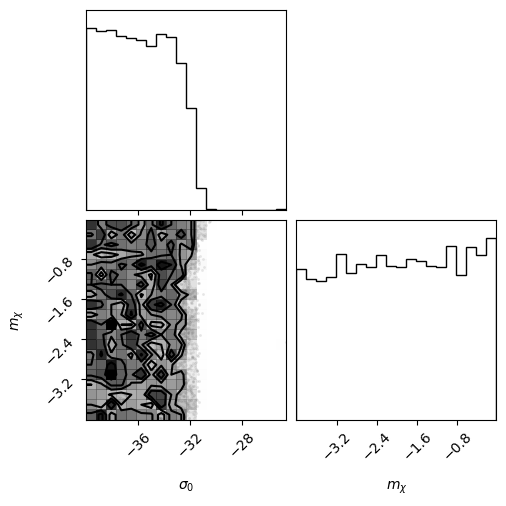

In [97]:
# generate corner plot
flat_samples2 = sampler2.get_chain(thin=15, flat=True)

print(flat_samples2.shape)

labels = [r"$\sigma_0$", r"$m_\chi$"]
fig2 = corner.corner(
    flat_samples2, labels=labels
);

In [98]:
print(
    "Mean acceptance fraction: {0:.3f}".format(
        np.mean(sampler2.acceptance_fraction)
    )
)
print(
    "Mean autocorrelation time: {0:.3f} steps".format(
        np.mean(sampler2.get_autocorr_time())
    )
)

Mean acceptance fraction: 0.624
Mean autocorrelation time: 49.624 steps
